# HomeValue — Exploratory Data Analysis

This notebook walks through the Ames, Iowa housing dataset that powers the HomeValue price estimate.
It is the exploratory companion to `src/data_preprocessing.py` and `src/train_model.py` — the production
pipeline applies the same cleaning logic in code.

**Dataset:** Ames Iowa Residential Housing Dataset (De Cock, 2011), retrieved from OpenML dataset 42165.

**What this notebook covers**
1. Load the raw extract and inspect its shape, types and missing values
2. Understand the target variable (`SalePrice`)
3. Clean the data and map raw codes to readable labels
4. Explore price against area, bedrooms, age, parking and location
5. Fit the two candidate models and compare them on a held-out test set
6. Inspect feature importance


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make the project root importable when running from notebooks/
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import config
from src.data_preprocessing import (
    build_preprocessor,
    clean_and_prepare_dataframe,
    inspect_dataset,
    load_raw_dataset,
)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)
print("Project root:", PROJECT_ROOT)

Project root: /home/user/house-price-prediction


## 1. Load and inspect the raw data

In [2]:
raw = load_raw_dataset()
report = inspect_dataset(raw)

print(f"Shape: {report['shape']['rows']} rows x {report['shape']['columns']} columns")
print(f"Duplicate rows: {report['duplicate_rows']}")
print(f"\nMissing values per column:\n{report['missing_values']}")
raw.head()

Shape: 1460 rows x 19 columns
Duplicate rows: 0

Missing values per column:
{'LotFrontage': 259, 'GarageType': 81}


,Id,Neighborhood,GrLivArea,LotArea,LotFrontage,BedroomAbvGr,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath,YearBuilt,YrSold,HouseStyle,GarageType,GarageCars,BldgType,OverallQual,OverallCond,SalePrice
0,1,CollgCr,1710,8450,65.0,3,2,1,1,0,2003,2008,2Story,Attchd,2,1Fam,7,5,208500
1,2,Veenker,1262,9600,80.0,3,2,0,0,1,1976,2007,1Story,Attchd,2,1Fam,6,8,181500
2,3,CollgCr,1786,11250,68.0,3,2,1,1,0,2001,2008,2Story,Attchd,2,1Fam,7,5,223500
3,4,Crawfor,1717,9550,60.0,3,1,0,1,0,1915,2006,2Story,Detchd,3,1Fam,7,5,140000
4,5,NoRidge,2198,14260,84.0,4,2,1,1,0,2000,2008,2Story,Attchd,3,1Fam,8,5,250000


In [3]:
raw.dtypes.to_frame("dtype").assign(n_missing=raw.isna().sum())

,dtype,n_missing
Id,int64,0
Neighborhood,object,0
GrLivArea,int64,0
LotArea,int64,0
LotFrontage,float64,259
BedroomAbvGr,int64,0
FullBath,int64,0
HalfBath,int64,0
BsmtFullBath,int64,0
BsmtHalfBath,int64,0


Only the columns needed by the app were kept in the raw extract. `LotFrontage` and `GarageType` carry
missing values — `GarageType` is meaningful (no garage), while `LotFrontage` is simply unused here.

## 2. The target variable

In [4]:
raw["SalePrice"].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.19589,79442.502883,34900.0,129975.0,163000.0,214000.0,755000.0


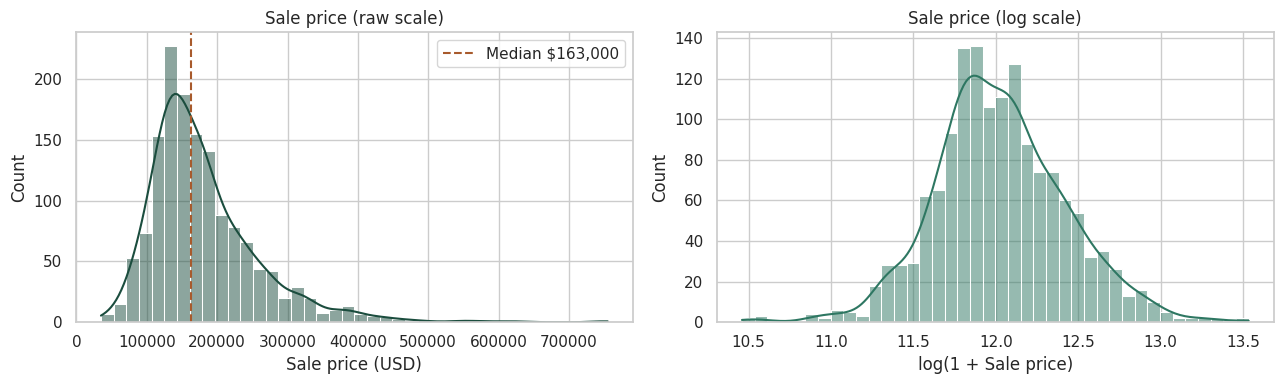

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(raw["SalePrice"], bins=40, kde=True, ax=axes[0], color="#1B4D3E")
axes[0].axvline(raw["SalePrice"].median(), color="#A85A2C", ls="--",
                label=f"Median ${raw['SalePrice'].median():,.0f}")
axes[0].set_title("Sale price (raw scale)")
axes[0].set_xlabel("Sale price (USD)")
axes[0].legend()

sns.histplot(np.log1p(raw["SalePrice"]), bins=40, kde=True, ax=axes[1], color="#2E7762")
axes[1].set_title("Sale price (log scale)")
axes[1].set_xlabel("log(1 + Sale price)")

plt.tight_layout()
plt.show()

The raw distribution is right-skewed; a log transform makes it far more symmetric. The production
pipeline deliberately models price on the **raw dollar scale**, because the app must report dollars and
a Random Forest handles the skew well. This is a conscious trade-off: RMSE is dominated by expensive
homes, which is why MAE and MAPE are reported alongside it.

## 3. Clean and map to the app's feature schema

In [6]:
clean, cleaning_summary = clean_and_prepare_dataframe(raw)
cleaning_summary

{'initial_rows': 1460,
 'duplicates_removed': 0,
 'anomalies_or_invalid_removed': 2,
 'final_rows': 1458,
 'remaining_missing_for_pipeline_imputation': {'bedrooms': 6}}

In [7]:
clean.head(10)

,location,area_sqft,lot_area_sqft,bedrooms,bathrooms,property_age,floors,parking,property_type,price
0,College Creek,1710.0,8450.0,3.0,3.5,5.0,2.0,2-Car Garage,Single-Family Detached,208500.0
1,Veenker,1262.0,9600.0,3.0,2.5,31.0,1.0,2-Car Garage,Single-Family Detached,181500.0
2,College Creek,1786.0,11250.0,3.0,3.5,7.0,2.0,2-Car Garage,Single-Family Detached,223500.0
3,Crawford,1717.0,9550.0,3.0,2.0,91.0,2.0,3+ Car Garage,Single-Family Detached,140000.0
4,Northridge,2198.0,14260.0,4.0,3.5,8.0,2.0,3+ Car Garage,Single-Family Detached,250000.0
5,Mitchell,1362.0,14115.0,1.0,2.5,16.0,1.5,2-Car Garage,Single-Family Detached,143000.0
6,Somerset,1694.0,10084.0,3.0,3.0,3.0,1.0,2-Car Garage,Single-Family Detached,307000.0
7,Northwest Ames,2090.0,10382.0,3.0,3.5,36.0,2.0,2-Car Garage,Single-Family Detached,200000.0
8,Old Town,1774.0,6120.0,2.0,2.0,77.0,1.5,2-Car Garage,Single-Family Detached,129900.0
9,Brookside,1077.0,7420.0,2.0,2.0,69.0,1.5,1-Car Garage,Two-Family Conversion,118000.0


In [8]:
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
area_sqft,1458.0,1510.465706,507.878508,334.0,1128.5,1461.5,1776.0,4476.0
lot_area_sqft,1458.0,10459.936900,9859.198156,1300.0,7544.5,9475.0,11600.0,215245.0
bedrooms,1452.0,2.878099,0.796886,1.0,2.0,3.0,3.0,8.0
bathrooms,1458.0,2.207476,0.781341,1.0,2.0,2.0,2.5,6.0
property_age,1458.0,36.598080,30.240565,0.0,8.0,35.0,54.0,136.0
floors,1458.0,1.403292,0.458927,1.0,1.0,1.0,2.0,2.5
price,1458.0,180932.919067,79495.055285,34900.0,129925.0,163000.0,214000.0,755000.0


Two documented anomalies were removed: very large homes (> 4,000 sq ft) sold below $300,000. De Cock
(2011) flags these as partial sales that were not complete at the time of recording.

Six records have zero above-grade bedrooms. Rather than dropping them, they are converted to `NaN` so
the `SimpleImputer` inside the pipeline fills them with the **training-set median**, which keeps the
imputation free of leakage.

## 4. Exploring relationships

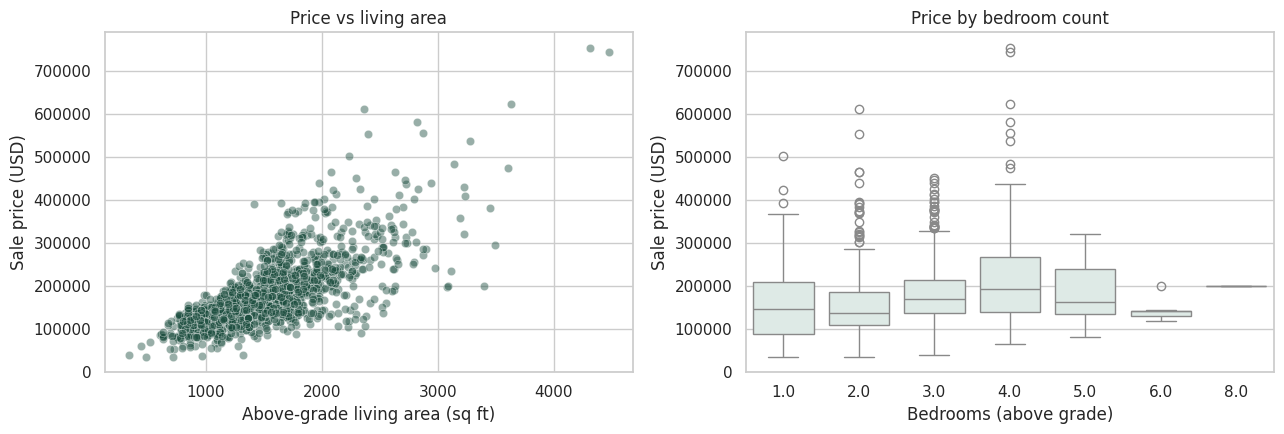

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=clean, x="area_sqft", y="price", alpha=0.45,
                color="#1B4D3E", ax=axes[0])
axes[0].set_title("Price vs living area")
axes[0].set_xlabel("Above-grade living area (sq ft)")
axes[0].set_ylabel("Sale price (USD)")

sns.boxplot(data=clean, x="bedrooms", y="price", color="#DCECE6", ax=axes[1])
axes[1].set_title("Price by bedroom count")
axes[1].set_xlabel("Bedrooms (above grade)")
axes[1].set_ylabel("Sale price (USD)")

plt.tight_layout()
plt.show()

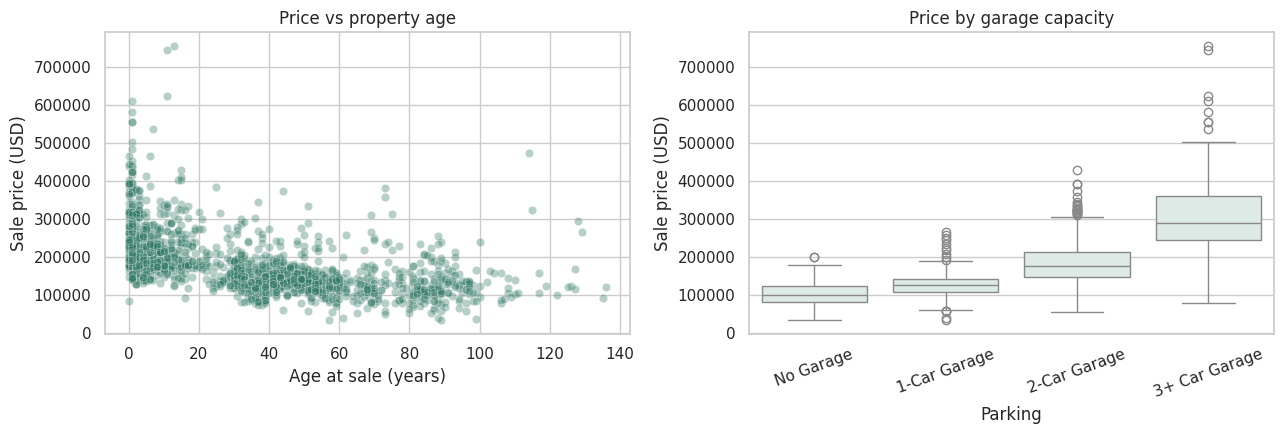

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=clean, x="property_age", y="price", alpha=0.35,
                color="#2E7762", ax=axes[0])
axes[0].set_title("Price vs property age")
axes[0].set_xlabel("Age at sale (years)")
axes[0].set_ylabel("Sale price (USD)")

sns.boxplot(data=clean, x="parking", y="price", color="#DCECE6", ax=axes[1],
            order=["No Garage", "1-Car Garage", "2-Car Garage", "3+ Car Garage"])
axes[1].set_title("Price by garage capacity")
axes[1].set_xlabel("Parking")
axes[1].set_ylabel("Sale price (USD)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

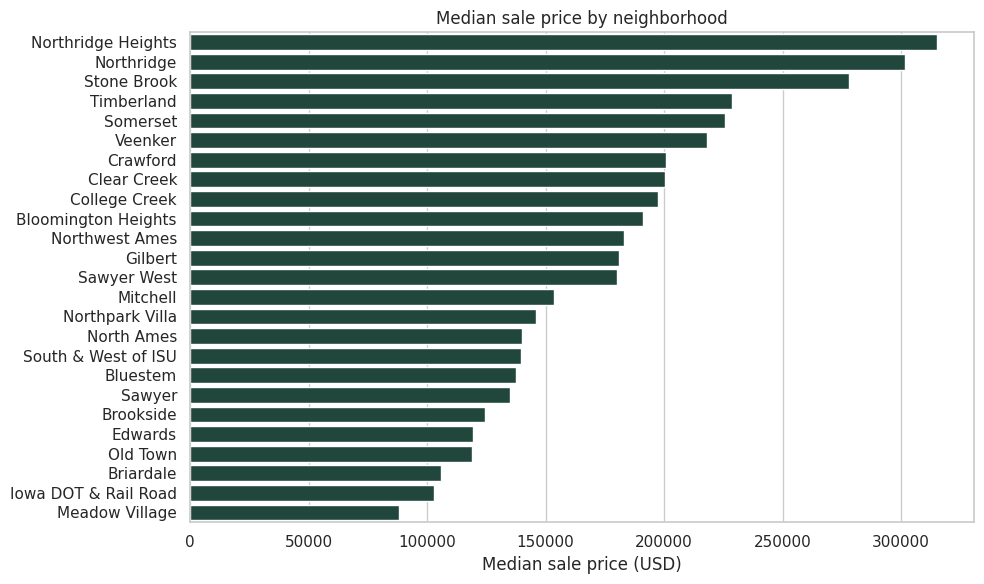

,count,median
location,,
Northridge Heights,77,315000.0
Northridge,41,301500.0
Stone Brook,25,278000.0
Timberland,38,228475.0
Somerset,86,225500.0
Veenker,11,218000.0
Crawford,51,200624.0
Clear Creek,28,200250.0
College Creek,150,197200.0


In [11]:
neighborhood = (
    clean.groupby("location")["price"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=neighborhood["median"], y=neighborhood.index, color="#1B4D3E", ax=ax)
ax.set_title("Median sale price by neighborhood")
ax.set_xlabel("Median sale price (USD)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

neighborhood.head(10)

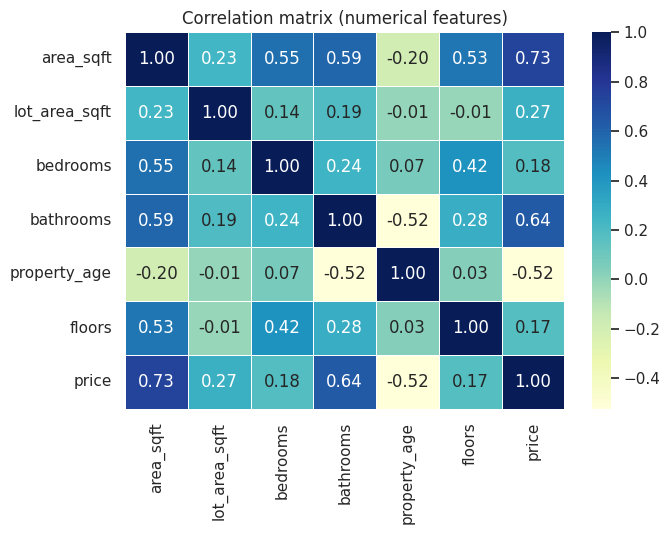

area_sqft        0.734968
bathrooms        0.635896
lot_area_sqft    0.268179
bedrooms         0.180966
floors           0.172797
property_age    -0.524067
Name: price, dtype: float64

In [12]:
correlation = clean[config.NUMERICAL_FEATURES + [config.TARGET_COLUMN]].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="YlGnBu",
            linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix (numerical features)")
plt.tight_layout()
plt.show()

correlation[config.TARGET_COLUMN].drop(config.TARGET_COLUMN).sort_values(ascending=False)

## 5. Train and compare the two candidate models

The split below is identical to the one used by `src/train_model.py` (80/20, `random_state=42`).
Preprocessing is fitted **only** on the training fold.

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

X = clean[config.ALL_FEATURES]
y = clean[config.TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 1166 rows | Test: 292 rows


In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=18, min_samples_split=4,
        random_state=config.RANDOM_STATE, n_jobs=-1,
    ),
}

rows = []
fitted = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", build_preprocessor()), ("model", estimator)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    for split, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        preds = pipe.predict(Xs)
        rows.append({
            "model": name,
            "split": split,
            "MAE": mean_absolute_error(ys, preds),
            "RMSE": root_mean_squared_error(ys, preds),
            "R2": r2_score(ys, preds),
        })

results = pd.DataFrame(rows)
results.style.format({"MAE": "${:,.0f}", "RMSE": "${:,.0f}", "R2": "{:.4f}"})

,model,split,MAE,RMSE,R2
0,Linear Regression,train,"$21,104","$30,610",0.8561
1,Linear Regression,test,"$21,974","$30,379",0.8329
2,Random Forest,train,"$8,325","$12,949",0.9743
3,Random Forest,test,"$19,039","$27,041",0.8676


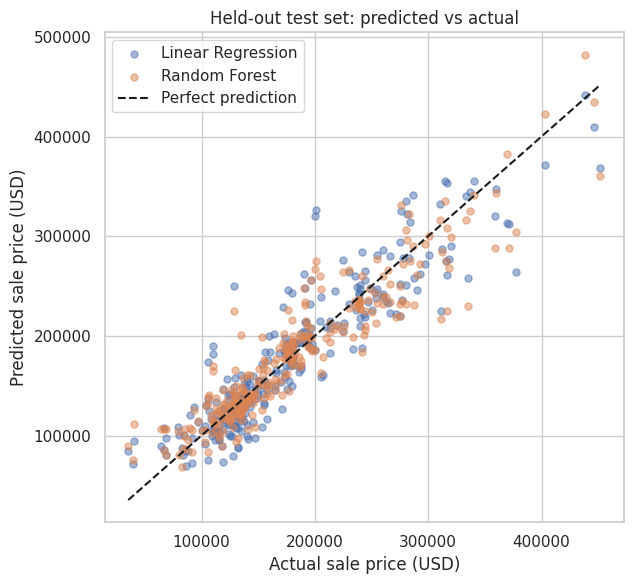

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, pipe in fitted.items():
    ax.scatter(y_test, pipe.predict(X_test), alpha=0.5, s=26, label=name)

limits = [y_test.min(), y_test.max()]
ax.plot(limits, limits, "k--", lw=1.5, label="Perfect prediction")
ax.set_xlabel("Actual sale price (USD)")
ax.set_ylabel("Predicted sale price (USD)")
ax.set_title("Held-out test set: predicted vs actual")
ax.legend()
plt.tight_layout()
plt.show()

The Random Forest wins on every held-out metric, so `src/train_model.py` selects it automatically. The
gap between train and test R² also shows the forest still fits the training data more closely than it
generalises — a hint that further regularisation would help.

## 6. Feature importance

In [16]:
from sklearn.inspection import permutation_importance

rf_pipe = fitted["Random Forest"]
pre = rf_pipe.named_steps["preprocessor"]
ohe = pre.named_transformers_["cat"].named_steps["onehot"]
importances = rf_pipe.named_steps["model"].feature_importances_

aggregated, idx = {}, 0
for col in config.NUMERICAL_FEATURES:
    aggregated[config.FEATURE_LABELS[col]] = importances[idx]
    idx += 1
for col, categories in zip(config.CATEGORICAL_FEATURES, ohe.categories_):
    aggregated[config.FEATURE_LABELS[col]] = importances[idx:idx + len(categories)].sum()
    idx += len(categories)

perm = permutation_importance(rf_pipe, X_test, y_test, n_repeats=10,
                              random_state=config.RANDOM_STATE, scoring="r2")

summary = (
    pd.DataFrame({
        "impurity": pd.Series(aggregated),
        "permutation": pd.Series(perm.importances_mean, index=X_test.columns)
        .rename(index=config.FEATURE_LABELS),
    })
    .sort_values("impurity", ascending=False)
)
summary.style.format({"impurity": "{:.1%}", "permutation": "{:.3f}"})

,impurity,permutation
Parking / Garage,35.1%,0.093
Living Area (sq ft),30.9%,0.485
Property Age (years),13.4%,0.265
Bathrooms,7.0%,0.036
Lot Size (sq ft),5.2%,0.033
Neighborhood / Location,3.7%,0.021
Bedrooms,2.5%,0.032
Floors / Stories,1.3%,0.022
Property Type,0.8%,0.008


Impurity importance favours high-cardinality splits, which is why it ranks garage capacity so highly.
Permutation importance — measured as the drop in held-out R² when a column is shuffled — tells a more
predictive story. Both are reported on the app's Insights page, and neither implies causation.

## 7. Try a prediction with the saved pipeline

In [17]:
from src.predict import predict_price

example = {
    "location": "Northridge Heights",
    "area_sqft": 2100,
    "lot_area_sqft": 12000,
    "bedrooms": 4,
    "bathrooms": 2.5,
    "property_age": 15,
    "floors": 2,
    "parking": "2-Car Garage",
    "property_type": "Single-Family Detached",
}

outcome = predict_price(example)
print(f"Estimated price: ${outcome['predicted_price']:,.2f}")
print(f"Price per sq ft: ${outcome['explanation']['predicted_price_per_sqft']:,.2f}")
outcome["explanation"]["sensitivity"]

Estimated price: $239,327.70
Price per sq ft: $113.97


[{'feature': 'property_age',
  'label': 'Property Age (years)',
  'delta': 10.0,
  'current_value': 15.0,
  'new_value': 25.0,
  'price_change': -17141.09},
 {'feature': 'area_sqft',
  'label': 'Living Area (sq ft)',
  'delta': 150.0,
  'current_value': 2100.0,
  'new_value': 2250.0,
  'price_change': 11071.36},
 {'feature': 'bathrooms',
  'label': 'Bathrooms',
  'delta': 1.0,
  'current_value': 2.5,
  'new_value': 3.5,
  'price_change': 6741.61},
 {'feature': 'bedrooms',
  'label': 'Bedrooms',
  'delta': 1.0,
  'current_value': 4.0,
  'new_value': 5.0,
  'price_change': -3472.09},
 {'feature': 'lot_area_sqft',
  'label': 'Lot Size (sq ft)',
  'delta': 1000.0,
  'current_value': 12000.0,
  'new_value': 13000.0,
  'price_change': 2146.5},
 {'feature': 'location',
  'label': 'Neighborhood / Location',
  'delta': None,
  'current_value': 'Northridge Heights',
  'new_value': 'Sawyer West',
  'price_change': -445.67},
 {'feature': 'floors',
  'label': 'Floors / Stories',
  'delta': -0.5,
  

## Next steps

Run `python -m src.train_model` from the project root to regenerate the pipeline, metrics and charts
after changing anything in this notebook's cleaning or modelling logic. The web app reads the saved
artifact, so it will pick up the new model on restart.